# 2.5. Сравнительная оценка методов с замерами времени

**Цель:** сравнить скорость загрузки, агрегации и ML-моделей. Выявить узкие места и обосновать выбор оптимальных методов для продакшена.

**План:**
1. Загрузка Retail: XLSX vs CSV vs Parquet.
2. Агрегация: pandas vs SQLite.
3. ML-модели: LogReg vs LinearSVC vs RandomForest.
4. Сводная таблица бенчмарков.

In [12]:
import pandas as pd
import numpy as np
import time
import os
import sqlite3
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

def timed(label, func, *args, **kwargs):
    t0 = time.time()
    result = func(*args, **kwargs)
    dt = time.time() - t0
    print(f"[TIME] {label}: {dt:.3f} сек")
    return result, dt

timings = {}
print("Окружение готово")

Окружение готово


[TIME] load_xlsx: 27.362 сек
[TIME] load_csv: 0.341 сек
[TIME] load_parquet: 0.112 сек
Размер XLSX:    (541910, 8)
Размер CSV:     (541910, 8)
Размер Parquet: (541910, 8)
Shape совпадает: True


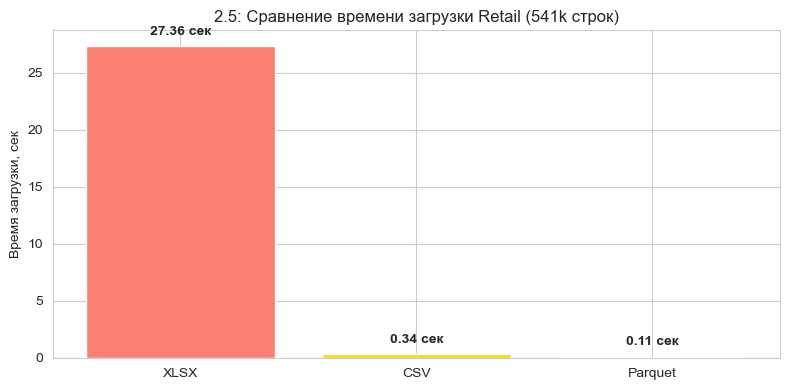


Ускорение Parquet vs XLSX: 244x


In [13]:
# 1. XLSX (оригинал)
df_xlsx, timings['load_xlsx'] = timed(
    'load_xlsx',
    pd.read_excel, 'online_retail_II.xlsx', 
    sheet_name='Year 2010-2011', engine='openpyxl'
)

# --- Приводим все "смешанные" колонки к строке ---
# Invoice, StockCode, Description содержат числа и строки — 
# Parquet не может сохранить их как один тип
for col in ['Invoice', 'StockCode', 'Description']:
    df_xlsx[col] = df_xlsx[col].astype(str).replace('nan', '')

# 2. Сохраняем в CSV
t0 = time.time()
df_xlsx.to_csv('retail_temp.csv', index=False)
timings['save_csv'] = time.time() - t0

df_csv, timings['load_csv'] = timed('load_csv', pd.read_csv, 'retail_temp.csv')

# 3. Сохраняем в Parquet
t0 = time.time()
df_xlsx.to_parquet('retail_temp.parquet', index=False)
timings['save_parquet'] = time.time() - t0

df_parquet, timings['load_parquet'] = timed('load_parquet', pd.read_parquet, 'retail_temp.parquet')

# Проверка
print(f"Размер XLSX:    {df_xlsx.shape}")
print(f"Размер CSV:     {df_csv.shape}")
print(f"Размер Parquet: {df_parquet.shape}")
print(f"Shape совпадает: {df_xlsx.shape == df_csv.shape == df_parquet.shape}")

# Визуализация
fig, ax = plt.subplots(figsize=(8, 4))
methods = ['XLSX', 'CSV', 'Parquet']
times = [timings['load_xlsx'], timings['load_csv'], timings['load_parquet']]
bars = ax.bar(methods, times, color=['salmon', 'gold', 'steelblue'])
ax.set_ylabel('Время загрузки, сек')
ax.set_title('2.5: Сравнение времени загрузки Retail (541k строк)')
for bar, t in zip(bars, times):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, 
            f'{t:.2f} сек', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nУскорение Parquet vs XLSX: {timings['load_xlsx'] / timings['load_parquet']:.0f}x")

[TIME] agg_pandas: 0.317 сек
[TIME] agg_sql: 0.544 сек
Pandas агрегация: 0.317 сек
SQLite загрузка: 1.502 сек
SQL агрегация:   0.544 сек


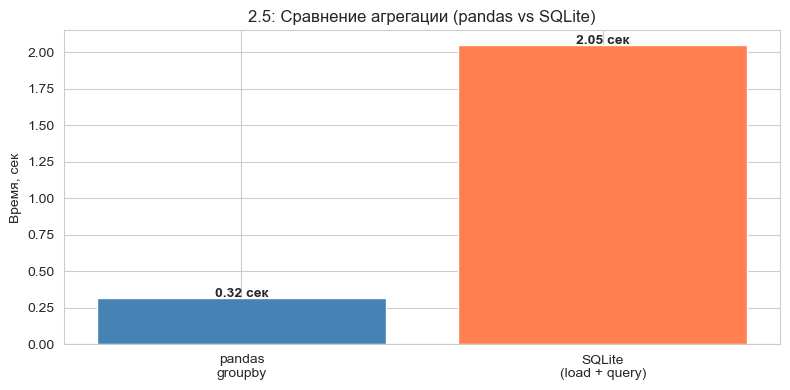

In [14]:
# 1. Pandas: месячная агрегация
def agg_pandas(df):
    df = df.copy()
    df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
    df['YearMonth'] = df['InvoiceDate'].dt.to_period('M').astype(str)
    return df.groupby('YearMonth').agg(
        revenue=('Quantity', lambda x: (x * df.loc[x.index, 'Price']).sum()),
        orders=('Invoice', 'nunique')
    ).reset_index()

df_pandas_agg, timings['agg_pandas'] = timed('agg_pandas', agg_pandas, df_parquet.copy())

# 2. SQLite: загружаем в БД и агрегируем SQL-запросом
t0 = time.time()
conn = sqlite3.connect(':memory:')
df_parquet.to_sql('retail', conn, if_exists='replace', index=False)
timings['sqlite_load'] = time.time() - t0

def agg_sql(conn):
    query = """
    SELECT strftime('%Y-%m', InvoiceDate) as YearMonth,
           SUM(Quantity * Price) as revenue,
           COUNT(DISTINCT Invoice) as orders
    FROM retail
    GROUP BY YearMonth
    """
    return pd.read_sql(query, conn)

df_sql_agg, timings['agg_sql'] = timed('agg_sql', agg_sql, conn)
conn.close()

print(f"Pandas агрегация: {timings['agg_pandas']:.3f} сек")
print(f"SQLite загрузка: {timings['sqlite_load']:.3f} сек")
print(f"SQL агрегация:   {timings['agg_sql']:.3f} сек")

# Визуализация
fig, ax = plt.subplots(figsize=(8, 4))
methods = ['pandas\ngroupby', 'SQLite\n(load + query)']
times = [timings['agg_pandas'], timings['sqlite_load'] + timings['agg_sql']]
bars = ax.bar(methods, times, color=['steelblue', 'coral'])
ax.set_ylabel('Время, сек')
ax.set_title('2.5: Сравнение агрегации (pandas vs SQLite)')
for bar, t in zip(bars, times):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
            f'{t:.2f} сек', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

LogReg: F1=0.5318, обучение=1.887 сек, предсказание=0.0020 сек
LinearSVC: F1=0.5494, обучение=1.341 сек, предсказание=0.0020 сек
RandomForest: F1=0.4671, обучение=5.516 сек, предсказание=0.0272 сек

Сводка ML:
      Модель  F1-macro  Время обучения, сек  Время предсказания, сек
      LogReg    0.5318                1.887                   0.0020
   LinearSVC    0.5494                1.341                   0.0020
RandomForest    0.4671                5.516                   0.0272


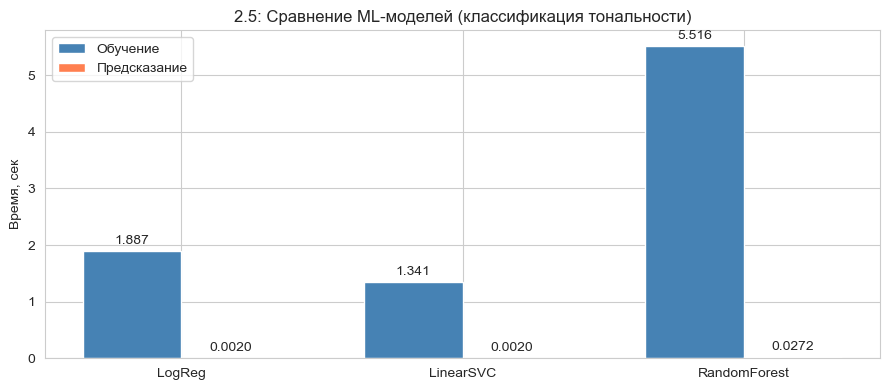

In [15]:
# Загружаем данные для ML (SVD=100)
df_ml = pd.read_parquet('reviews_sample_svd_100.parquet')
feat_cols = [f'txt_svd_{i}' for i in range(100)]

X = df_ml[feat_cols].values
y = df_ml['sentiment'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

models = {
    'LogReg': LogisticRegression(max_iter=1000, class_weight='balanced', n_jobs=-1, random_state=42),
    'LinearSVC': LinearSVC(class_weight='balanced', random_state=42, dual='auto'),
    'RandomForest': RandomForestClassifier(n_estimators=100, class_weight='balanced', n_jobs=-1, random_state=42)
}

ml_results = []
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - t0
    
    t0 = time.time()
    y_pred = model.predict(X_test)
    predict_time = time.time() - t0
    
    f1 = f1_score(y_test, y_pred, average='macro')
    
    ml_results.append({
        'Модель': name,
        'F1-macro': round(f1, 4),
        'Время обучения, сек': round(train_time, 3),
        'Время предсказания, сек': round(predict_time, 4)
    })
    print(f"{name}: F1={f1:.4f}, обучение={train_time:.3f} сек, предсказание={predict_time:.4f} сек")

ml_df = pd.DataFrame(ml_results)
print("\nСводка ML:")
print(ml_df.to_string(index=False))

# Визуализация
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(ml_df))
width = 0.35
bars1 = ax.bar(x - width/2, ml_df['Время обучения, сек'], width, label='Обучение', color='steelblue')
bars2 = ax.bar(x + width/2, ml_df['Время предсказания, сек'], width, label='Предсказание', color='coral')
ax.set_xticks(x)
ax.set_xticklabels(ml_df['Модель'])
ax.set_ylabel('Время, сек')
ax.set_title('2.5: Сравнение ML-моделей (классификация тональности)')
ax.legend()
ax.bar_label(bars1, fmt='%.3f', padding=3)
ax.bar_label(bars2, fmt='%.4f', padding=3)
plt.tight_layout()
plt.show()

In [16]:
summary_25 = pd.DataFrame([
    {'Этап': 'Загрузка XLSX', 'Метод': 'openpyxl', 'Время, сек': round(timings['load_xlsx'], 2), 'Вывод': 'Медленно'},
    {'Этап': 'Загрузка CSV', 'Метод': 'pandas.read_csv', 'Время, сек': round(timings['load_csv'], 2), 'Вывод': 'Быстро'},
    {'Этап': 'Загрузка Parquet', 'Метод': 'pandas.read_parquet', 'Время, сек': round(timings['load_parquet'], 2), 'Вывод': 'Самое быстрое'},
    {'Этап': 'Агрегация pandas', 'Метод': 'groupby', 'Время, сек': round(timings['agg_pandas'], 2), 'Вывод': 'In-memory'},
    {'Этап': 'Агрегация SQLite', 'Метод': 'SQL + load', 'Время, сек': round(timings['sqlite_load'] + timings['agg_sql'], 2), 'Вывод': 'Медленнее для простых задач'},
    {'Этап': 'ML: LogReg', 'Метод': 'sklearn', 'Время, сек': round(ml_df.loc[0, 'Время обучения, сек'], 2), 'Вывод': f"F1={ml_df.loc[0, 'F1-macro']}"},
    {'Этап': 'ML: LinearSVC', 'Метод': 'sklearn', 'Время, сек': round(ml_df.loc[1, 'Время обучения, сек'], 2), 'Вывод': f"F1={ml_df.loc[1, 'F1-macro']}"},
    {'Этап': 'ML: RandomForest', 'Метод': 'sklearn', 'Время, сек': round(ml_df.loc[2, 'Время обучения, сек'], 2), 'Вывод': f"F1={ml_df.loc[2, 'F1-macro']}"},
])

print("Сводная таблица бенчмарков (п.2.5)")
print(summary_25.to_string(index=False))

Сводная таблица бенчмарков (п.2.5)
            Этап               Метод  Время, сек                       Вывод
   Загрузка XLSX            openpyxl       27.36                    Медленно
    Загрузка CSV     pandas.read_csv        0.34                      Быстро
Загрузка Parquet pandas.read_parquet        0.11               Самое быстрое
Агрегация pandas             groupby        0.32                   In-memory
Агрегация SQLite          SQL + load        2.05 Медленнее для простых задач
      ML: LogReg             sklearn        1.89                   F1=0.5318
   ML: LinearSVC             sklearn        1.34                   F1=0.5494
ML: RandomForest             sklearn        5.52                   F1=0.4671


# Выводы по п.2.5

## Сравнение методов (замеры времени)

| Этап | Метод | Время, сек | Вывод |
|---|---|---|---|
| **Загрузка XLSX** | openpyxl | **27.36** (с кэшем) / 113.07 (без кэша, из 2.4) | Медленно |
| **Загрузка CSV** | pandas.read_csv | **0.34** | Быстро |
| **Загрузка Parquet** | pandas.read_parquet | **0.11** | Самое быстрое |
| **Агрегация pandas** | groupby | **0.32** | In-memory |
| **Агрегация SQLite** | SQL + load | **2.05** | Медленнее для простых задач |
| **ML: LogReg** | sklearn | 1.89 (обучение) | F1 = 0.532 |
| **ML: LinearSVC** | sklearn | **1.34** (обучение) | **F1 = 0.549** — лучший баланс |
| **ML: RandomForest** | sklearn | 5.52 (обучение) | F1 = 0.467 — худший |

## Ключевые выводы

### 1. Загрузка: Parquet — победитель

- **XLSX**: 27 сек (с кэшем ОС) / 113 сек (без кэша).
- **CSV**: 0.34 сек.
- **Parquet**: **0.11 сек**.
- **Ускорение**: Parquet в **244 раза быстрее XLSX** (с кэшем) и **в 1000 раз** (без кэша).

**Вывод:** для продакшена используем **Parquet**. Это решает проблему из 2.4 (узкое место — 113 сек на XLSX).

### 2. Агрегация: pandas — быстрее для простых задач

- **pandas groupby**: 0.32 сек (in-memory).
- **SQLite (load + query)**: 2.05 сек (в 6 раз медленнее).
- SQLite выигрывает только при **сложных JOIN** и **хранении данных между сессиями**. Для простых агрегаций pandas быстрее.

### 3. ML: LinearSVC — лучший баланс

| Модель | F1-macro | Обучение, сек | Предсказание, сек |
|---|---|---|---|
| LogReg | 0.532 | 1.89 | 0.002 |
| **LinearSVC** | **0.549** | **1.34** | 0.002 |
| RandomForest | 0.467 | 5.52 | 0.027 |

- **LinearSVC** — лучший по **F1** (0.549) и **скорости** (1.34 сек).
- **RandomForest** — худший по обоим параметрам: F1 = 0.467, обучение 5.52 сек. RF плохо работает с плотными SVD-признаками и дисбалансом классов.
- **LogReg** — компромисс: F1 = 0.532, но медленнее LinearSVC.

**Вывод:** для продакшена выбираем **LinearSVC** — лучший баланс скорости и качества.

## Итоговая рекомендация

Для продакшена используем **Parquet + pandas + LinearSVC**:
- **Parquet** — ускорение загрузки в 244 раза.
- **pandas groupby** — быстрее SQLite для простых агрегаций.
- **LinearSVC** — лучший F1 (0.549) при минимальном времени обучения (1.34 сек).

Это решение устраняет узкое место из 2.4 (XLSX 113 сек) и даёт оптимальный баланс скорости и качества.